# Fourier Analysis Demo
Showcase of base experiments to analyse Fourier space of solution

## 0 - Setup

In [13]:
%load_ext autoreload
%autoreload 2

import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models  import MerlinHeatQPINN, ClassicalHeatQPINN, MerlinTunableSimple, MerlinTunableEntropy
from src.pde     import HeatEquation, WaveEquation
from src.loss    import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import (
    plot_training_history,
    plot_solution_comparison,
    plot_power_spectrum,
    plot_mode_l2_errors,
    plot_frequency_sweep,
    plot_multi_model_l2_error
)
from src.utils import hilbert_space_dimension, quantum_outputsize_for_param_match, find_matching_hidden_readout

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cpu  |  dtype: torch.float32


## 1 - Frequency Sweep
Train both models on heat equatin over a range of IC frequencies

In [2]:
FREQUENCIES = [0.5, 1.5, 2.5, 3.5, 4.5, 5.5]
#FREQUENCIES = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0]
SEEDS = [42, 666, 69]#, 67, 13]
#SEEDS = [120]

In [3]:
FEATURE_SIZES_guess = [4]#[2,4,8,16]
FEATURE_SIZE, HIDDEN_READOUT = find_matching_hidden_readout(feature_sizes=FEATURE_SIZES_guess, ranges=[1,100])

print(FEATURE_SIZE)
print(HIDDEN_READOUT)
#select smallest
FEATURE_SIZE = FEATURE_SIZE[0]
HIDDEN_READOUT = HIDDEN_READOUT[0]
QUANTUM_OUTPUT_SIZE = int(quantum_outputsize_for_param_match(FEATURE_SIZE, HIDDEN_READOUT))

[[  1   1]
 [  1   2]
 [  1   3]
 ...
 [ 98 100]
 [ 99 100]
 [100 100]]
[4]
[4]


In [ ]:
sweep_results = {"classical": [], "qpinn_weights": []} #"qpinn": [], 
for freq in FREQUENCIES:
    pde = HeatEquation(freq=freq, alpha=1.0)
    #pde = WaveEquation(freq=freq,c=0.5)
    print(f"\n{'='*60}\nfreq = {freq}")
    seed_results = {"classical": [], "qpinn_weights": []}
    for i,seed in enumerate(SEEDS):
        # --- QPINN ---
#        qpinn = MerlinHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=pde).to(device)
#        train(model=qpinn, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
#        metrics, _, _, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)
#        sweep_results["qpinn"].append({"frequency": freq, "rel_l2": metrics["rel_l2"]})
#        print(f"  QPINN_SEED_{seed}      rel_l2 = {metrics['rel_l2']:.4e}")

        # --- Classical ---
        classical = ClassicalHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, quantum_output_size=QUANTUM_OUTPUT_SIZE, pde = pde).to(device)
        train(model=classical, pde=pde, loss_fn=total_loss, log_every=100, seed=seed, epochs=600)
        metrics, _, _, _, _ = evaluate(model=classical, pde=pde, device=device, dtype=dtype)
        seed_results["classical"].append(metrics["rel_l2"])
        
        print(f"  Classical_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")

        # --- QPINN WEIGHTS ---
        qpinn_weights = MerlinTunableSimple(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=pde).to(device)
        train(model=qpinn_weights, pde=pde, loss_fn=total_loss, log_every=100, seed=seed, epochs=600)
        metrics, _, _, _, _ = evaluate(model=qpinn_weights, pde=pde, device=device, dtype=dtype)
        seed_results["qpinn_weights"].append(metrics["rel_l2"])
        print(f"  QPINN WEIGHTS_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")
    
    sweep_results["classical"].append({"frequency": freq, "rel_l2": seed_results["classical"]})
    sweep_results["qpinn_weights"].append({"frequency": freq, "rel_l2": seed_results["qpinn_weights"]})



freq = 0.5
Parameters — total: 310  trainable: 310

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 4.5805e+00 | PDE: 4.58e-03 | Cons: 1.58e-01 | IC: 4.50e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch   100/600 | Loss: 2.2591e-01 | PDE: 8.25e-02 | Cons: 2.57e-01 | IC: 1.51e-03 | BC: 0.00e+00 | Time: 0.3s
Epoch   200/600 | Loss: 2.3666e-01 | PDE: 9.76e-03 | Cons: 4.42e-01 | IC: 6.01e-04 | BC: 0.00e+00 | Time: 0.5s
Epoch   300/600 | Loss: 1.1364e-01 | PDE: 3.80e-03 | Cons: 2.14e-01 | IC: 2.68e-04 | BC: 0.00e+00 | Time: 0.7s
Epoch   400/600 | Loss: 1.2328e-01 | PDE: 3.07e-03 | Cons: 2.39e-01 | IC: 8.48e-05 | BC: 0.00e+00 | Time: 0.9s
Epoch   500/600 | Loss: 2.6011e-01 | PDE: 7.20e-03 | Cons: 4.98e-01 | IC: 3.85e-04 | BC: 0.00e+00 | Time: 1.1s
Epoch   600/600 | Loss: 2.6015e-01 | PDE: 1.44e-02 | Cons: 4.91e-01 | IC: 2.09e-05 | BC: 0.00e+00 | Time: 1.3s

Done — 1.3s total
Evaluating on 60×60 grid …
  Relative L2 : 6.8871e-02
  MAE         : 1.0559e-02
  Max abs err : 

Saved: ../figures/fourier_demo/freq_sweep.png


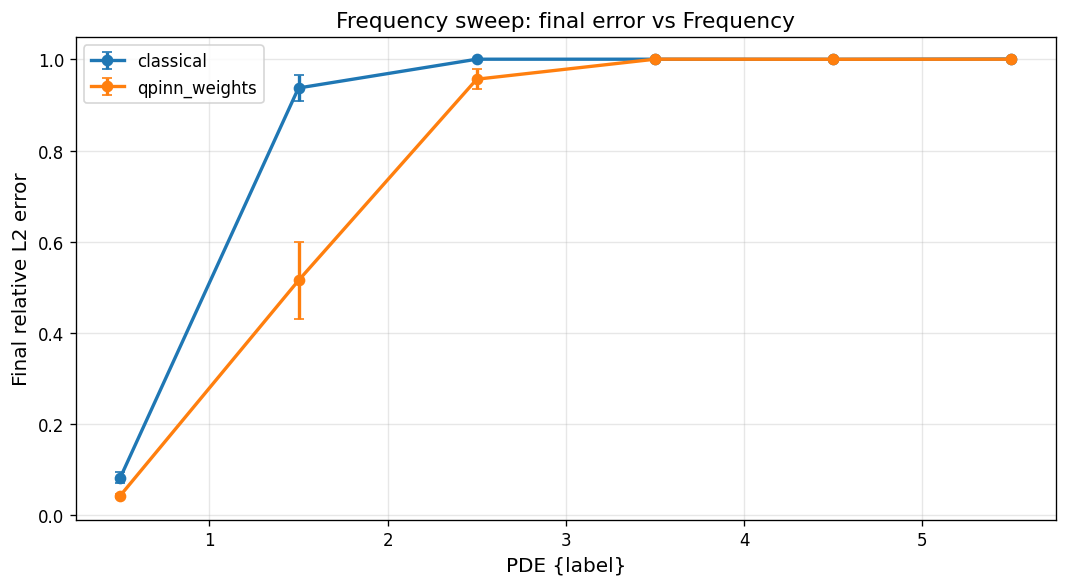

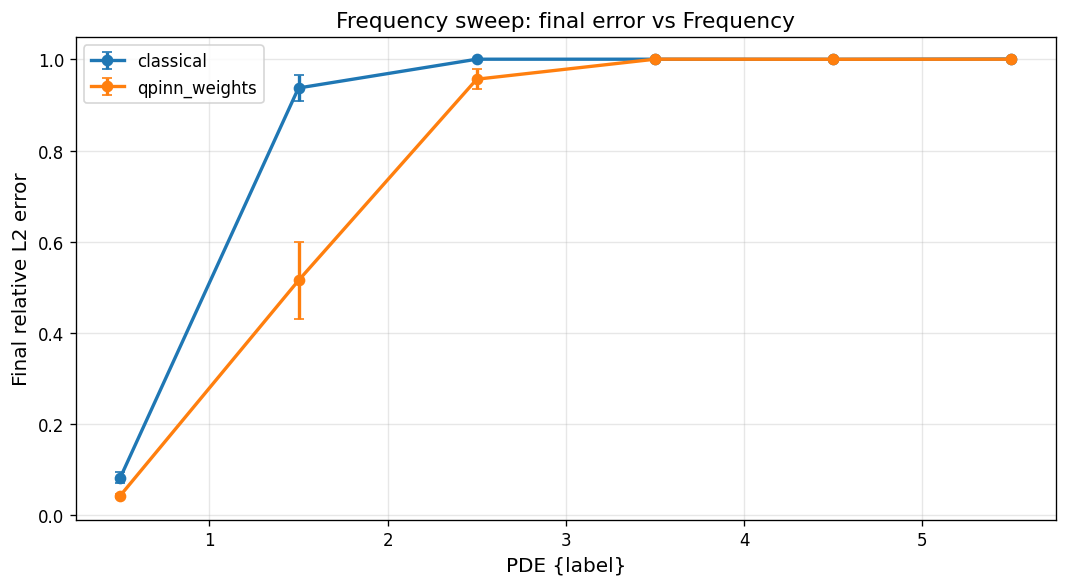

In [6]:
%reload_ext autoreload
plot_frequency_sweep(
    sweep_results,
    save_path = "../figures/fourier_demo/freq_sweep.png",
    show      = True,
)

## 2 - Train both models with same frequency and compare

In [24]:
FREQUENCY = 1.0
N_EPOCHS = 4000

Parameters — total: 310  trainable: 310

Training for 2000 epochs on cpu  (dtype=torch.float32)
Epoch     1/2000 | Loss: 5.3564e+00 | PDE: 3.33e-05 | Cons: 1.50e-01 | IC: 5.28e-01 | BC: 0.00e+00 | Time: 0.0s
Epoch    50/2000 | Loss: 4.9694e+00 | PDE: 4.64e-05 | Cons: 3.44e-03 | IC: 4.97e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch   100/2000 | Loss: 4.9395e+00 | PDE: 6.18e-06 | Cons: 7.69e-05 | IC: 4.94e-01 | BC: 0.00e+00 | Time: 0.2s
Epoch   150/2000 | Loss: 4.7464e+00 | PDE: 3.70e-05 | Cons: 6.31e-03 | IC: 4.74e-01 | BC: 0.00e+00 | Time: 0.3s
Epoch   200/2000 | Loss: 4.7422e+00 | PDE: 3.60e-05 | Cons: 1.17e-03 | IC: 4.74e-01 | BC: 0.00e+00 | Time: 0.4s
Epoch   250/2000 | Loss: 5.4403e+00 | PDE: 1.74e-04 | Cons: 6.97e-03 | IC: 5.44e-01 | BC: 0.00e+00 | Time: 0.5s
Epoch   300/2000 | Loss: 5.0914e+00 | PDE: 9.00e-03 | Cons: 9.61e-03 | IC: 5.08e-01 | BC: 0.00e+00 | Time: 0.7s
Epoch   350/2000 | Loss: 4.5168e+00 | PDE: 1.93e-02 | Cons: 1.52e-02 | IC: 4.49e-01 | BC: 0.00e+00 | Time: 0.8s
Epoch   

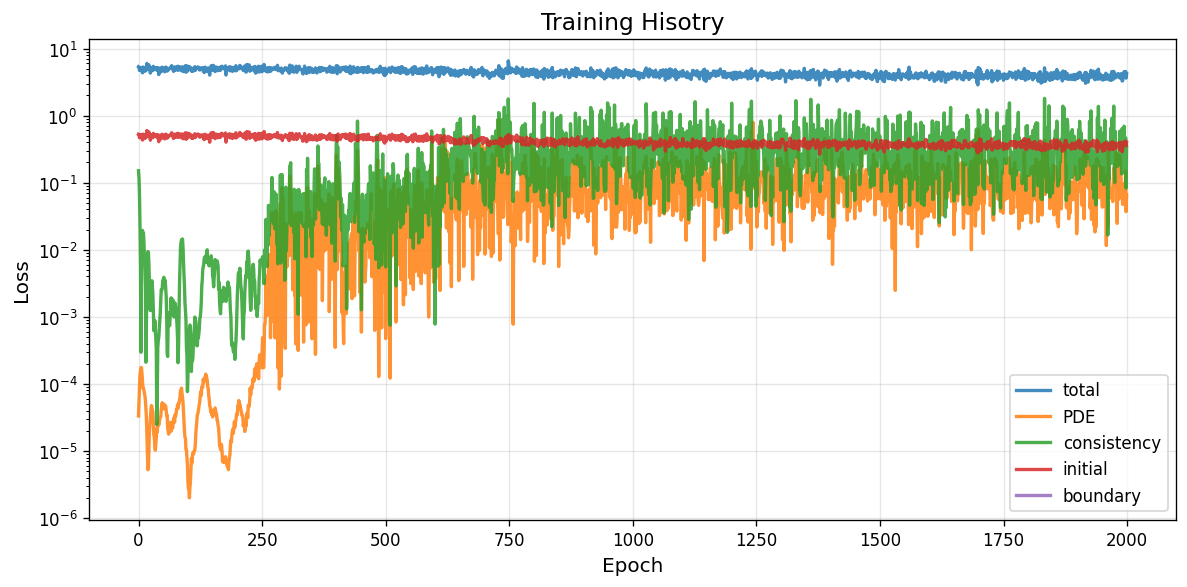

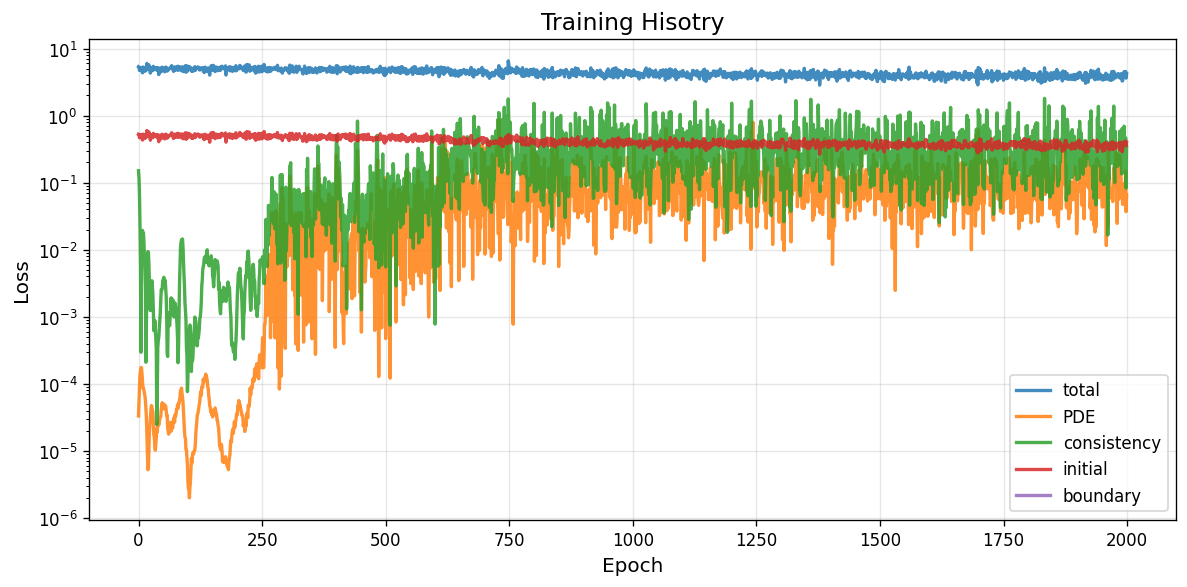

In [20]:

ref_pde = HeatEquation(freq=FREQUENCY, alpha=0.01)
#ref_pde = WaveEquation(freq=FREQUENCY, c=1.5)

# QPINN
#qpinn_ref = MerlinHeatQPINN().to(device)
#history_q = train(model=qpinn_ref, pde=ref_pde, epochs = 600)

# Classical
classical_ref = ClassicalHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, quantum_output_size=QUANTUM_OUTPUT_SIZE, pde = ref_pde).to(device)
history_c = train(model=classical_ref, pde=ref_pde, epochs = N_EPOCHS)

plot_training_history(
    history_c,
    save_path ='../figures/fourier_demo/history_c.png',  # set to None to skip saving
    show      = True,
)


Parameters — total: 310  trainable: 310

Training for 4000 epochs on cpu  (dtype=torch.float32)
Epoch     1/4000 | Loss: 5.2994e+00 | PDE: 3.09e-05 | Cons: 5.34e-02 | IC: 5.27e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch    50/4000 | Loss: 4.9704e+00 | PDE: 1.68e-06 | Cons: 3.21e-04 | IC: 4.97e-01 | BC: 0.00e+00 | Time: 4.2s
Epoch   100/4000 | Loss: 4.9488e+00 | PDE: 1.08e-05 | Cons: 3.25e-03 | IC: 4.95e-01 | BC: 0.00e+00 | Time: 8.2s
Epoch   150/4000 | Loss: 4.4050e+00 | PDE: 6.08e-02 | Cons: 5.17e-01 | IC: 4.09e-01 | BC: 0.00e+00 | Time: 12.0s
Epoch   200/4000 | Loss: 2.7858e+00 | PDE: 1.49e-01 | Cons: 7.32e-01 | IC: 2.27e-01 | BC: 0.00e+00 | Time: 15.8s
Epoch   250/4000 | Loss: 3.1791e+00 | PDE: 2.05e-01 | Cons: 9.50e-01 | IC: 2.50e-01 | BC: 0.00e+00 | Time: 19.9s
Epoch   300/4000 | Loss: 2.6386e+00 | PDE: 2.41e-01 | Cons: 5.20e-01 | IC: 2.14e-01 | BC: 0.00e+00 | Time: 23.9s
Epoch   350/4000 | Loss: 2.4819e+00 | PDE: 1.72e-01 | Cons: 1.21e+00 | IC: 1.70e-01 | BC: 0.00e+00 | Time: 27.8s
Epo

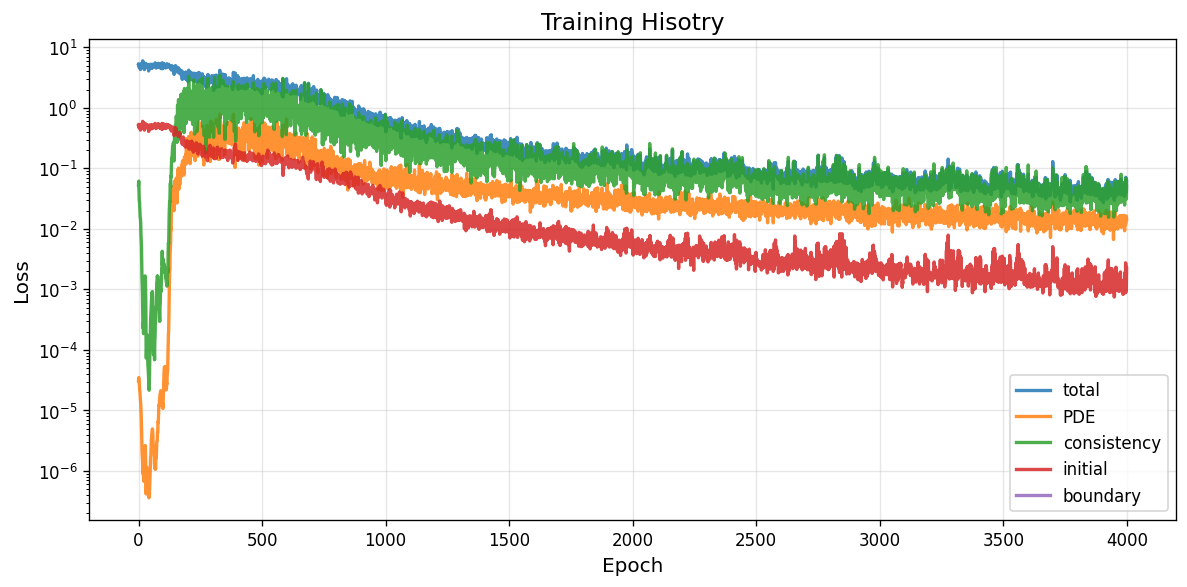

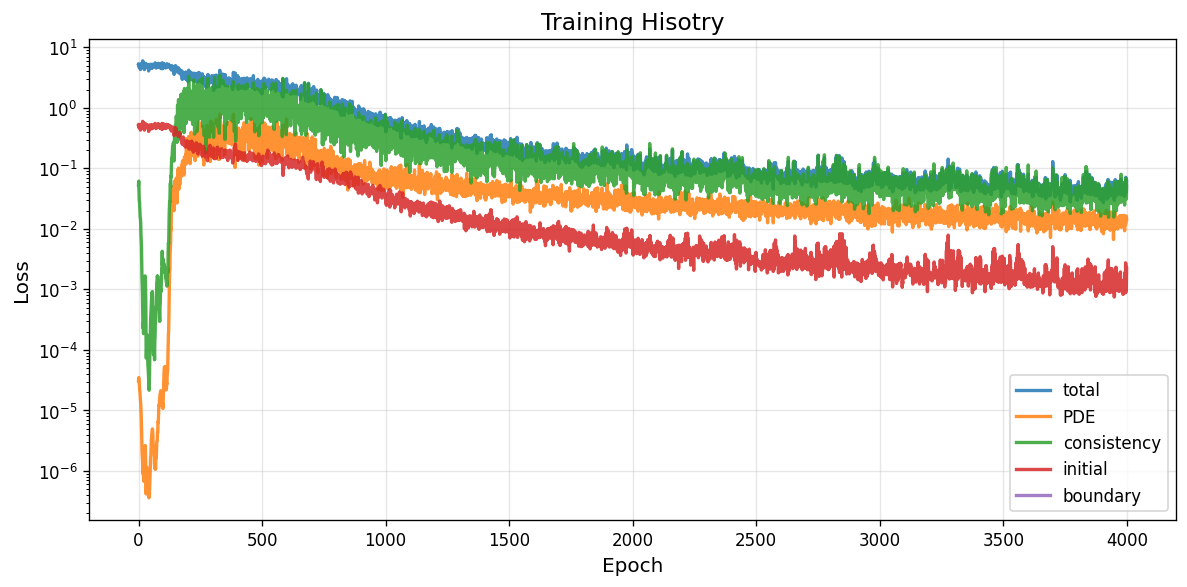

In [25]:

qpinn_weights_ref = MerlinTunableSimple(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=ref_pde).to(device)
history_qpinn_weights = train(model=qpinn_weights_ref, pde=ref_pde, epochs = N_EPOCHS)

plot_training_history(
    history_qpinn_weights,
    save_path ='../figures/fourier_demo/history_q.png',  # set to None to skip saving
    show      = True,
)

In [30]:
# Evaluate models
grid_n = 128


#_, U_pred_q, U_true, x_grid, t_grid = evaluate(model=qpinn_ref, pde=ref_pde,
#                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_c, U_true,      _,      _      = evaluate(model=classical_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_q_w, _,      _,      _      = evaluate(model=qpinn_weights_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

Evaluating on 128×128 grid …
  Relative L2 : 9.8805e-01
  MAE         : 8.3923e-02
  Max abs err : 1.0433e+00
  RMSE        : 1.7025e-01
Evaluating on 128×128 grid …
  Relative L2 : 6.6029e-01
  MAE         : 5.6848e-02
  Max abs err : 7.8847e-01
  RMSE        : 1.1377e-01


#TODO : figure out here Q error is smaller than C error ??? this doesnt match results from other pipeline

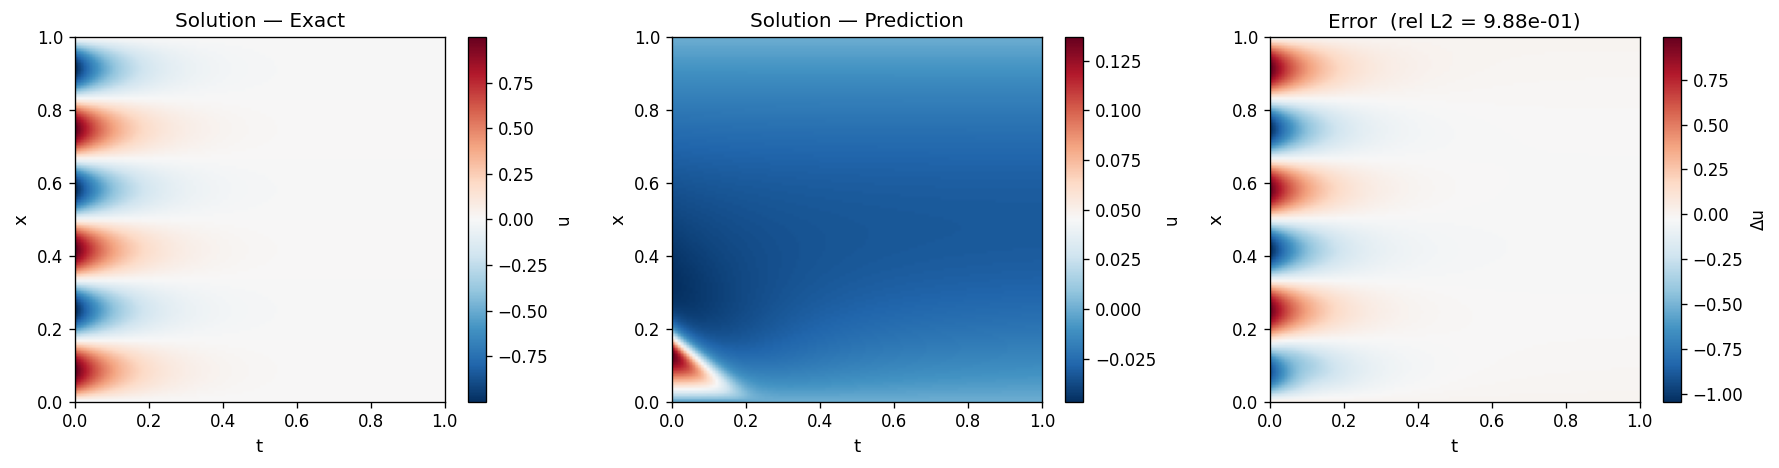

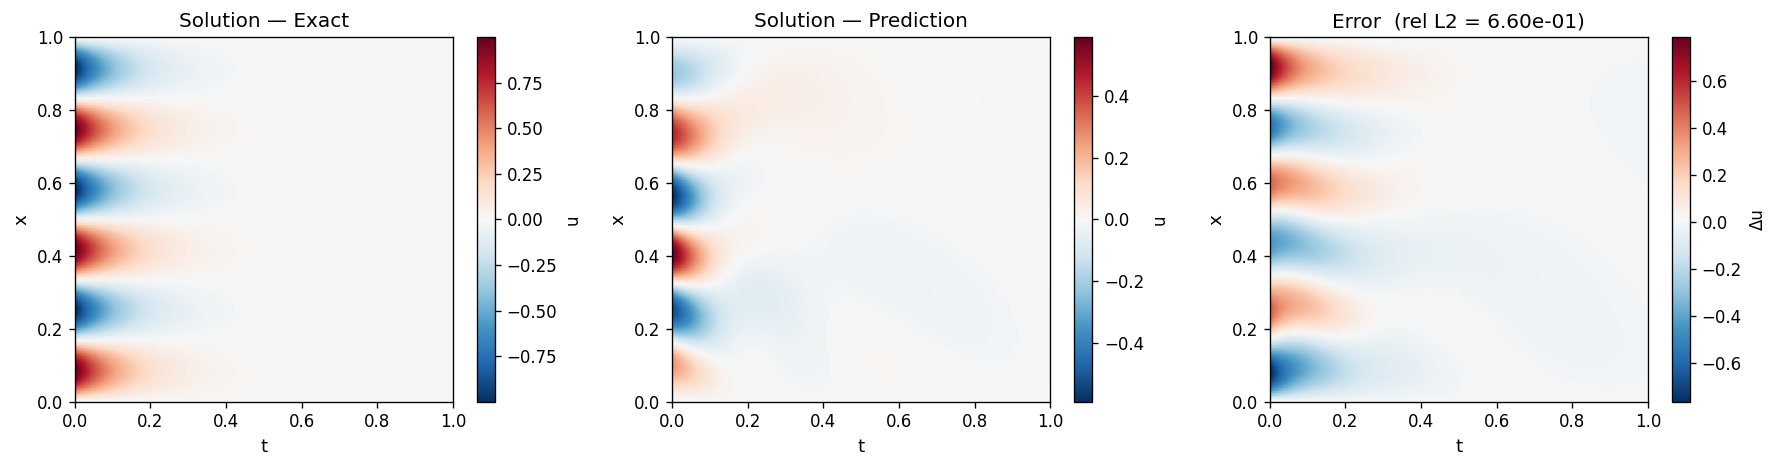

(<Figure size 1800x480 with 6 Axes>, 0.6602858901023865)

In [31]:
#plot_solution_comparison(U_pred_q,U_true)
plot_solution_comparison(U_pred_c,U_true)
plot_solution_comparison(U_pred_q_w,U_true)


### 2.1 - Compare power spectra

Classical power spectrum
Saved: ../figures/demo_fourier/power_spectrum_c.png


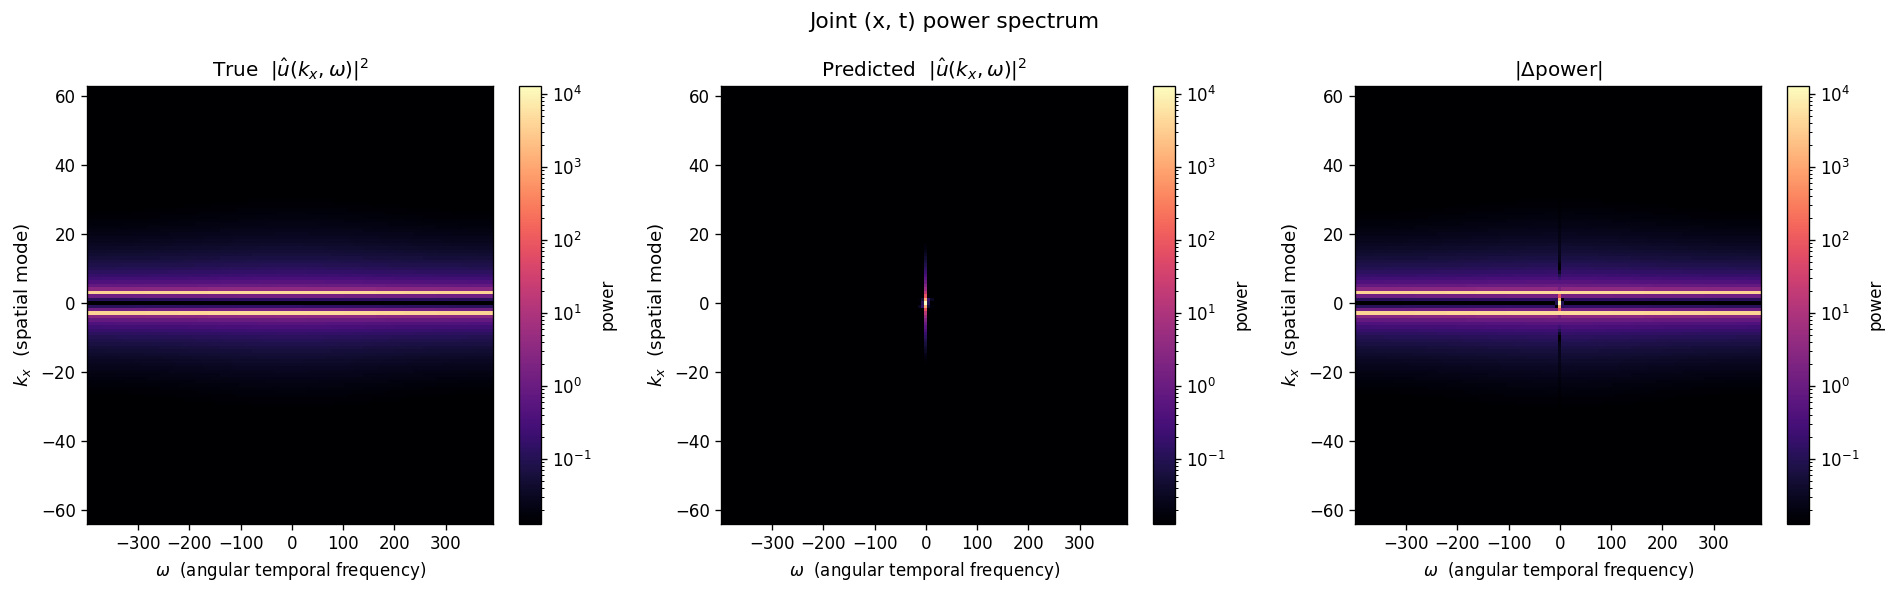

QPINN_weights power spectrum
Saved: ../figures/demo_fourier/power_spectrum_c.png


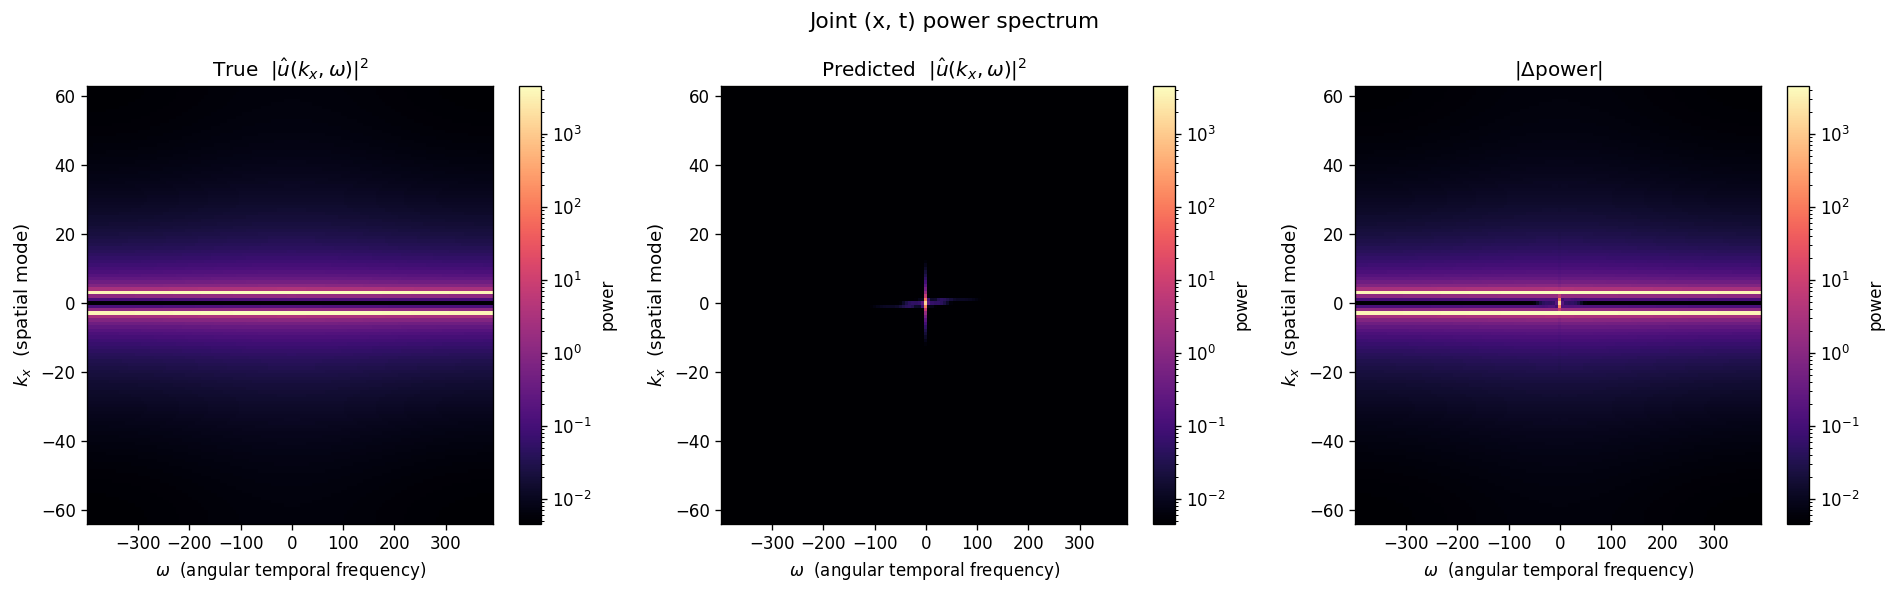

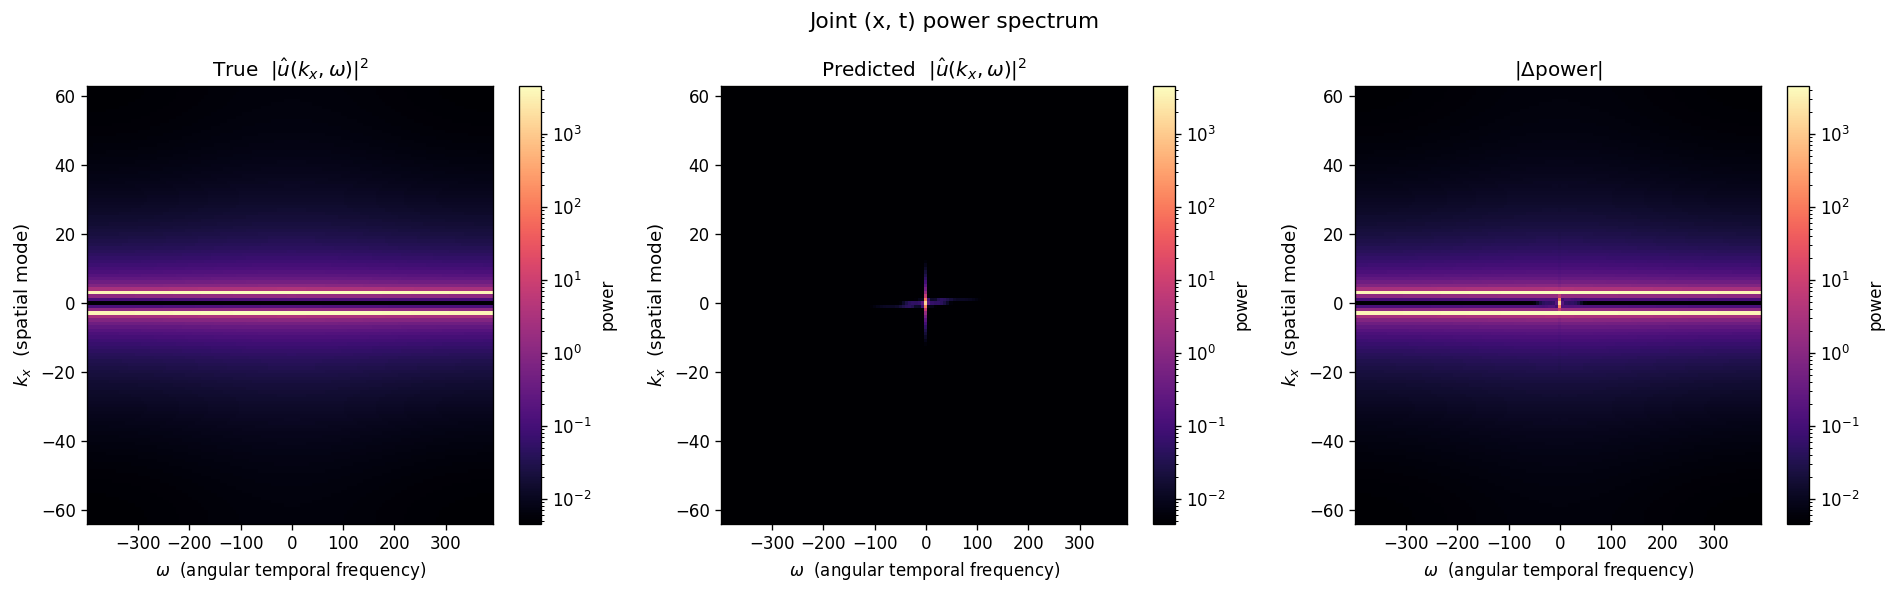

In [21]:
#print("QPINN power spectrum")
#plot_power_spectrum(U_pred_q, U_true, save_path="../figures/demo_fourier/power_spectrum_q.png", exclude_0_mode=False)

print("Classical power spectrum")
plot_power_spectrum(U_pred_c, U_true, save_path="../figures/demo_fourier/power_spectrum_c.png", exclude_0_mode=False)

print("QPINN_weights power spectrum")
plot_power_spectrum(U_pred_q_w, U_true, save_path="../figures/demo_fourier/power_spectrum_c.png", exclude_0_mode=False)



### 2.2 Compare per-mode L2 error

In [35]:
print("QPINN mode errors")
plot_mode_l2_errors(U_pred_q, U_true,
                    save_path="../figures/fourier_demo/l2_error_Q.png")

print("Classical mode errors")
plot_mode_l2_errors(U_pred_c, U_true,
                    save_path="../figures/fourier_demo/l2_error_C.png")

print("QPINN_weights mode errors")
plot_mode_l2_errors(U_pred_q_w, U_true,
                    save_path="../figures/fourier_demo/l2_error_Q_weights.png")



QPINN mode errors


NameError: name 'U_pred_q' is not defined

## Compare directly

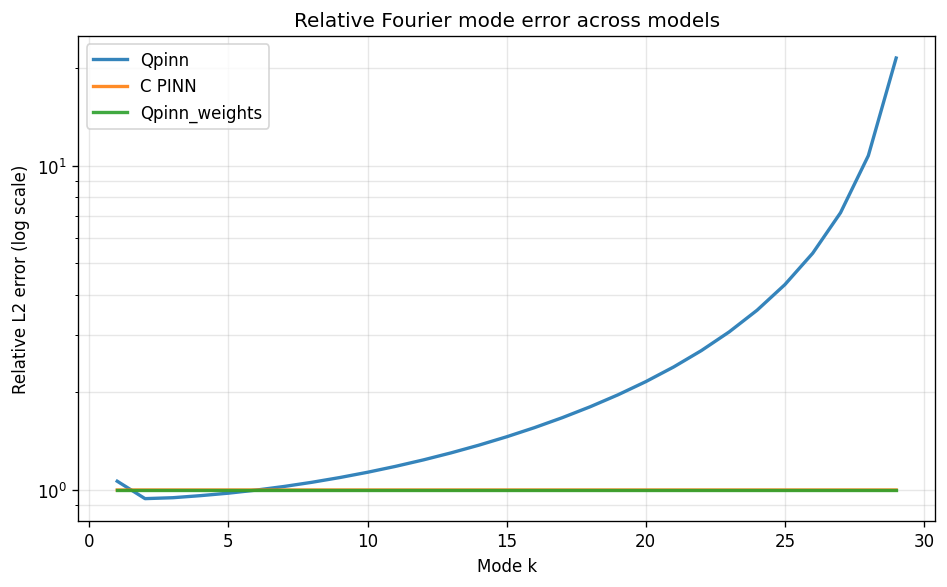

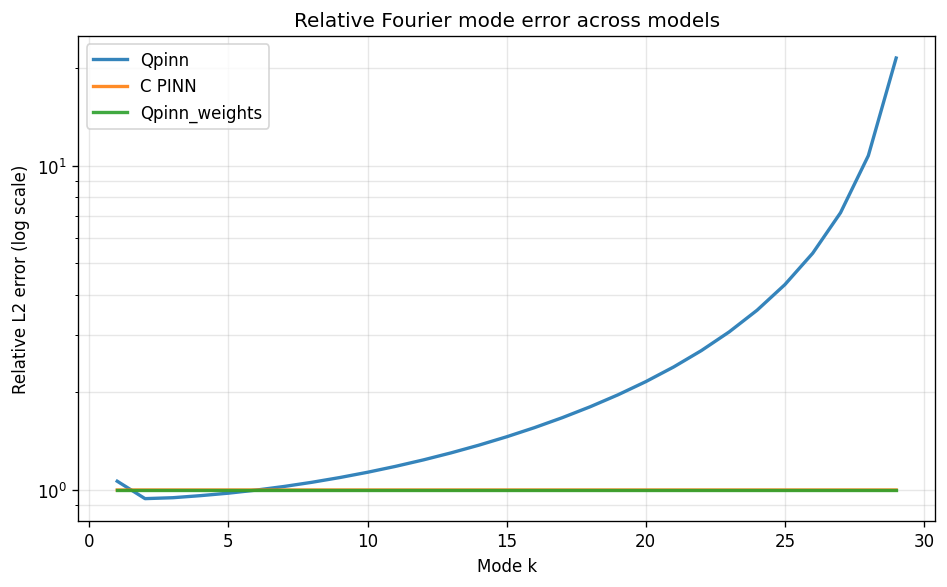

In [16]:


plot_multi_model_l2_error(U_true, [U_pred_q, U_pred_c,U_pred_q_w],["Qpinn", "C PINN","Qpinn_weights"])

In [44]:
from src.sweep import get_matched_widths, run_2d_sweep
from src.plotter import plot_2d_sweep

%reload_ext autoreload
# Change this to change how many weights the compared models have — reuses
# the same param-matching logic as section 1 (find_matching_hidden_readout /
# quantum_outputsize_for_param_match), just wrapped for a single feature_size.
# Bigger feature_size -> more weights for BOTH models (matched), but grows
# fast (quantum_output_size scales with the Hilbert space dimension).
FEATURE_SIZE_2D_GUESS = 4

FEATURE_SIZE_2D, HIDDEN_READOUT_2D, QUANTUM_OUTPUT_SIZE_2D = get_matched_widths(FEATURE_SIZE_2D_GUESS)
print(f"feature_size={FEATURE_SIZE_2D}  hidden_readout={HIDDEN_READOUT_2D}  "
      f"quantum_output_size={QUANTUM_OUTPUT_SIZE_2D}")

SEEDS_2D = [42]#, 666, 67, 1, 1000]   # fewer seeds than section 1 by default -- 2-D sweeps are expensive
EPOCHS_2D = 600


[[  1   1]
 [  1   2]
 [  1   3]
 ...
 [ 98 100]
 [ 99 100]
 [100 100]]
feature_size=4  hidden_readout=4  quantum_output_size=20


In [45]:

#FREQS_HEAT = [0.5, 1.0, 1.5, 2.5, 3.5]
FREQS_HEAT = [0.5, 1.5, 2.5, 3.5, 4.5]
#ALPHAS_HEAT = [0.01, 0.025, 0.05, 0.1]
#ALPHAS_HEAT = [0.001, 0.01, 0.1]
ALPHAS_HEAT = [0.001, 0.01, 0.1]

heat_sweep = run_2d_sweep(
    pde_factory=lambda freq, alpha: HeatEquation(freq=freq, alpha=alpha),
    param1_name="freq", param1_values=FREQS_HEAT,
    param2_name="alpha", param2_values=ALPHAS_HEAT,
    feature_size=FEATURE_SIZE_2D, hidden_readout=HIDDEN_READOUT_2D,
    quantum_output_size=QUANTUM_OUTPUT_SIZE_2D,
    seeds=SEEDS_2D, epochs=EPOCHS_2D, log_every=50,
)


Parameters — total: 310  trainable: 310

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 3.8930e+00 | PDE: 4.44e-05 | Cons: 3.68e-01 | IC: 3.71e-01 | BC: 0.00e+00 | Time: 0.0s
Epoch    50/600 | Loss: 1.8554e+00 | PDE: 1.70e-05 | Cons: 2.52e+00 | IC: 5.94e-02 | BC: 0.00e+00 | Time: 0.1s
Epoch   100/600 | Loss: 9.1681e-01 | PDE: 2.86e-01 | Cons: 9.66e-01 | IC: 1.48e-02 | BC: 0.00e+00 | Time: 0.2s
Epoch   150/600 | Loss: 8.2519e-01 | PDE: 1.80e-01 | Cons: 1.02e+00 | IC: 1.36e-02 | BC: 0.00e+00 | Time: 0.3s
Epoch   200/600 | Loss: 3.1393e-01 | PDE: 8.29e-02 | Cons: 2.91e-01 | IC: 8.55e-03 | BC: 0.00e+00 | Time: 0.4s
Epoch   250/600 | Loss: 2.8217e-02 | PDE: 4.84e-03 | Cons: 2.70e-02 | IC: 9.90e-04 | BC: 0.00e+00 | Time: 0.5s
Epoch   300/600 | Loss: 9.2206e-03 | PDE: 1.37e-03 | Cons: 7.97e-03 | IC: 3.87e-04 | BC: 0.00e+00 | Time: 0.6s
Epoch   350/600 | Loss: 5.1550e-03 | PDE: 9.47e-04 | Cons: 3.88e-03 | IC: 2.27e-04 | BC: 0.00e+00 | Time: 0.7s
Epoch   400/600 |

Saved: ../figures/fourier_demo/heat_sweep_freq_alpha_rel_l2_FS=4.png


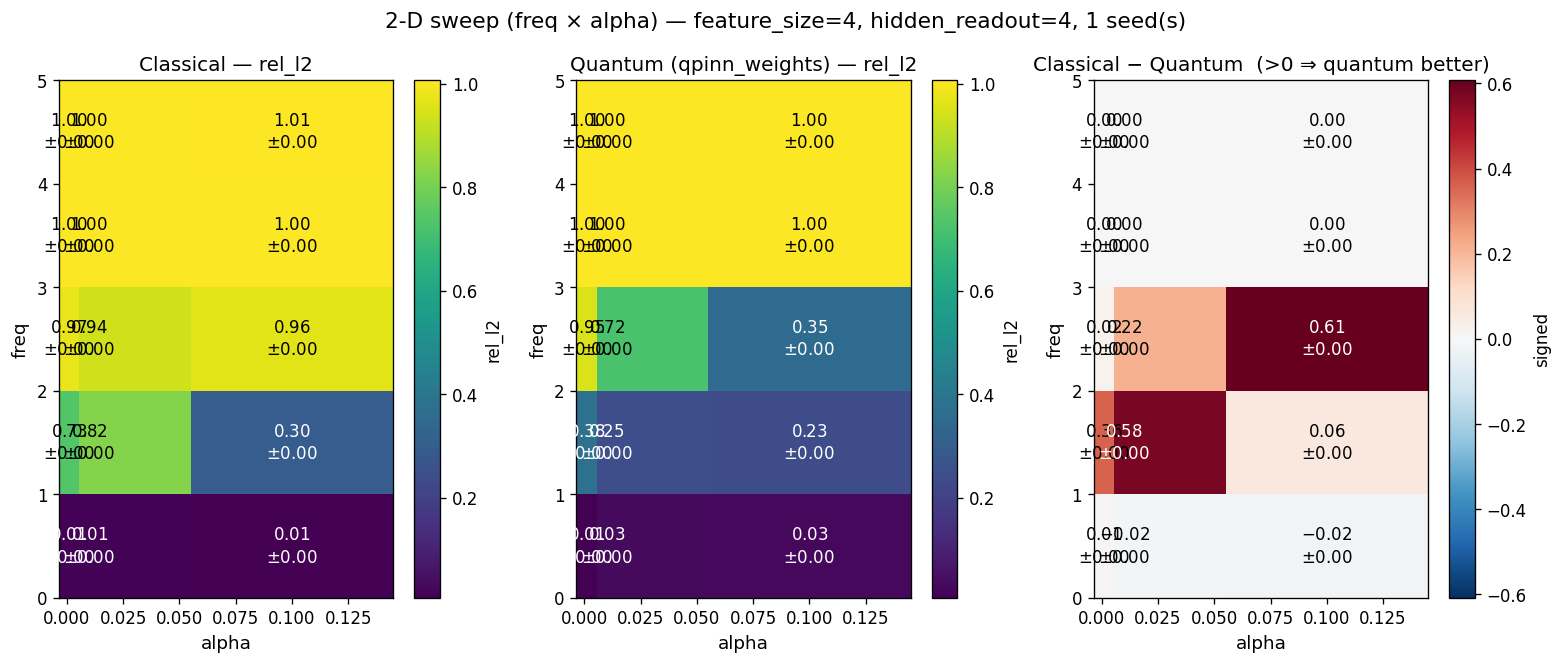

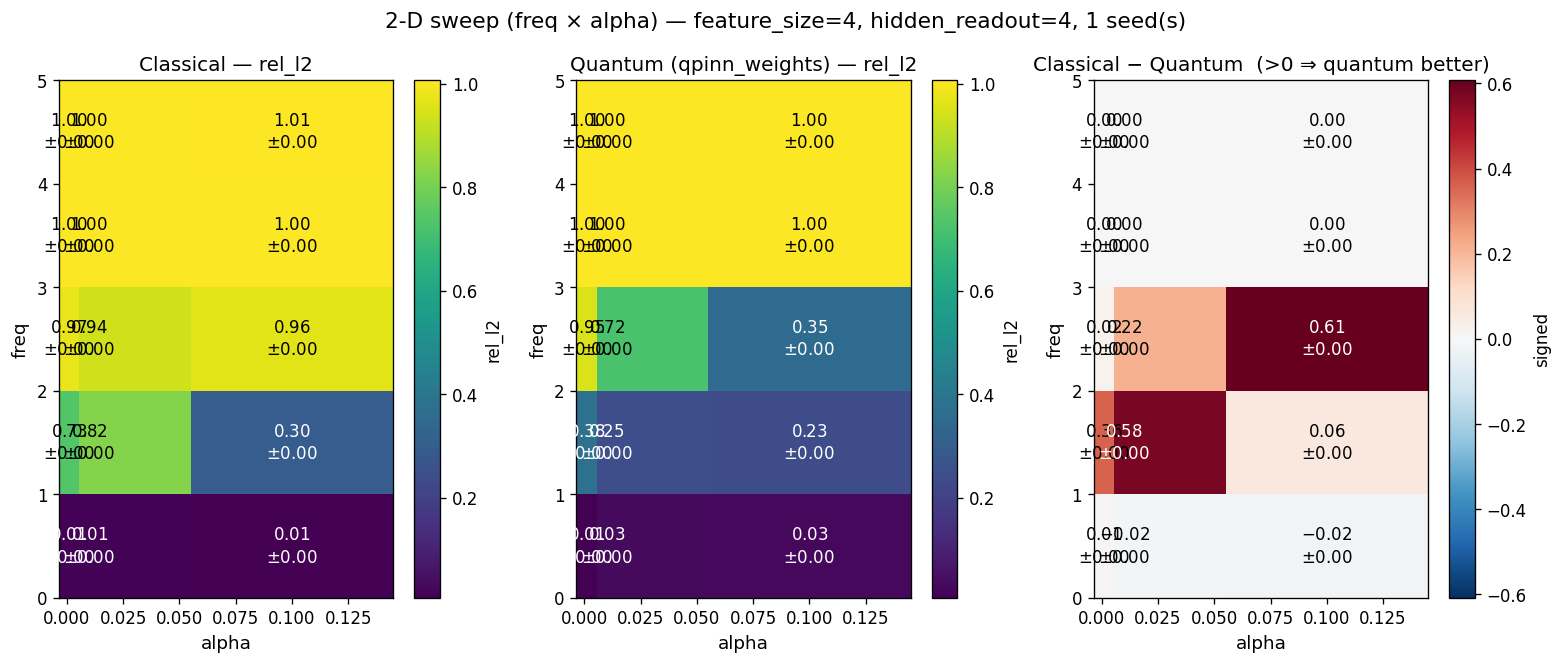

In [46]:
# metric can be "rel_l2", "mae", "max_abs_error", or "rmse"
plot_2d_sweep(
    heat_sweep, metric="rel_l2", diff_mode="signed",
    save_path=f"../figures/fourier_demo/heat_sweep_freq_alpha_rel_l2_FS={FEATURE_SIZE_2D_GUESS}.png",
)

In [43]:
#FREQS_WAVE = [0.5, 1.5, 2.5, 3.5]
FREQS_WAVE = [0.5, 1.5, 2.5, 3.5]
#CS_WAVE = [0.25, 0.5, 1.0, 2.0]
CS_WAVE = [0.5, 1.0, 1.5, 2.0]

wave_sweep = run_2d_sweep(
    pde_factory=lambda freq, c: WaveEquation(freq=freq, c=c),
    param1_name="freq", param1_values=FREQS_WAVE,
    param2_name="c", param2_values=CS_WAVE,
    feature_size=FEATURE_SIZE_2D, hidden_readout=HIDDEN_READOUT_2D,
    quantum_output_size=QUANTUM_OUTPUT_SIZE_2D,
    seeds=SEEDS_2D, epochs=EPOCHS_2D, log_every=50,
)

Parameters — total: 310  trainable: 310

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 5.4939e+00 | PDE: 2.73e-02 | Cons: 4.44e-02 | IC: 5.44e-01 | BC: 0.00e+00 | Time: 0.0s
Epoch    50/600 | Loss: 2.0382e+00 | PDE: 2.88e-01 | Cons: 6.67e-01 | IC: 1.42e-01 | BC: 0.00e+00 | Time: 0.3s
Epoch   100/600 | Loss: 1.1614e+00 | PDE: 1.83e-01 | Cons: 1.39e+00 | IC: 2.81e-02 | BC: 0.00e+00 | Time: 0.6s
Epoch   150/600 | Loss: 1.1132e+00 | PDE: 1.91e-01 | Cons: 1.39e+00 | IC: 2.25e-02 | BC: 0.00e+00 | Time: 0.9s
Epoch   200/600 | Loss: 9.5502e-01 | PDE: 5.85e-02 | Cons: 1.36e+00 | IC: 2.16e-02 | BC: 0.00e+00 | Time: 1.2s
Epoch   250/600 | Loss: 7.0799e-01 | PDE: 7.04e-02 | Cons: 9.56e-01 | IC: 1.60e-02 | BC: 0.00e+00 | Time: 1.5s
Epoch   300/600 | Loss: 5.1237e-01 | PDE: 5.08e-02 | Cons: 6.02e-01 | IC: 1.61e-02 | BC: 0.00e+00 | Time: 1.8s
Epoch   350/600 | Loss: 4.2000e-01 | PDE: 5.53e-02 | Cons: 4.35e-01 | IC: 1.47e-02 | BC: 0.00e+00 | Time: 2.1s
Epoch   400/600 |

KeyboardInterrupt: 

Saved: ../figures/fourier_demo/wave_sweep_freq_c_rel_l2_FS=4_.png


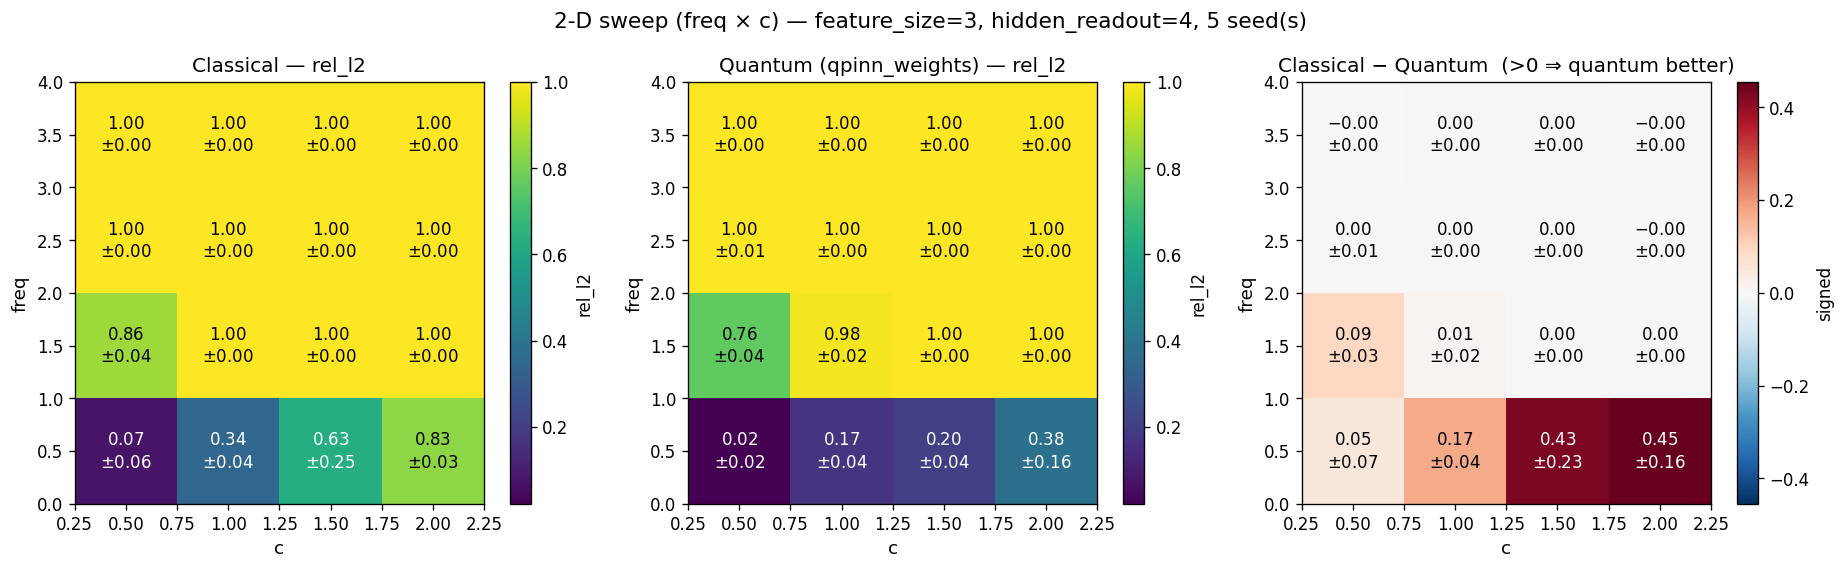

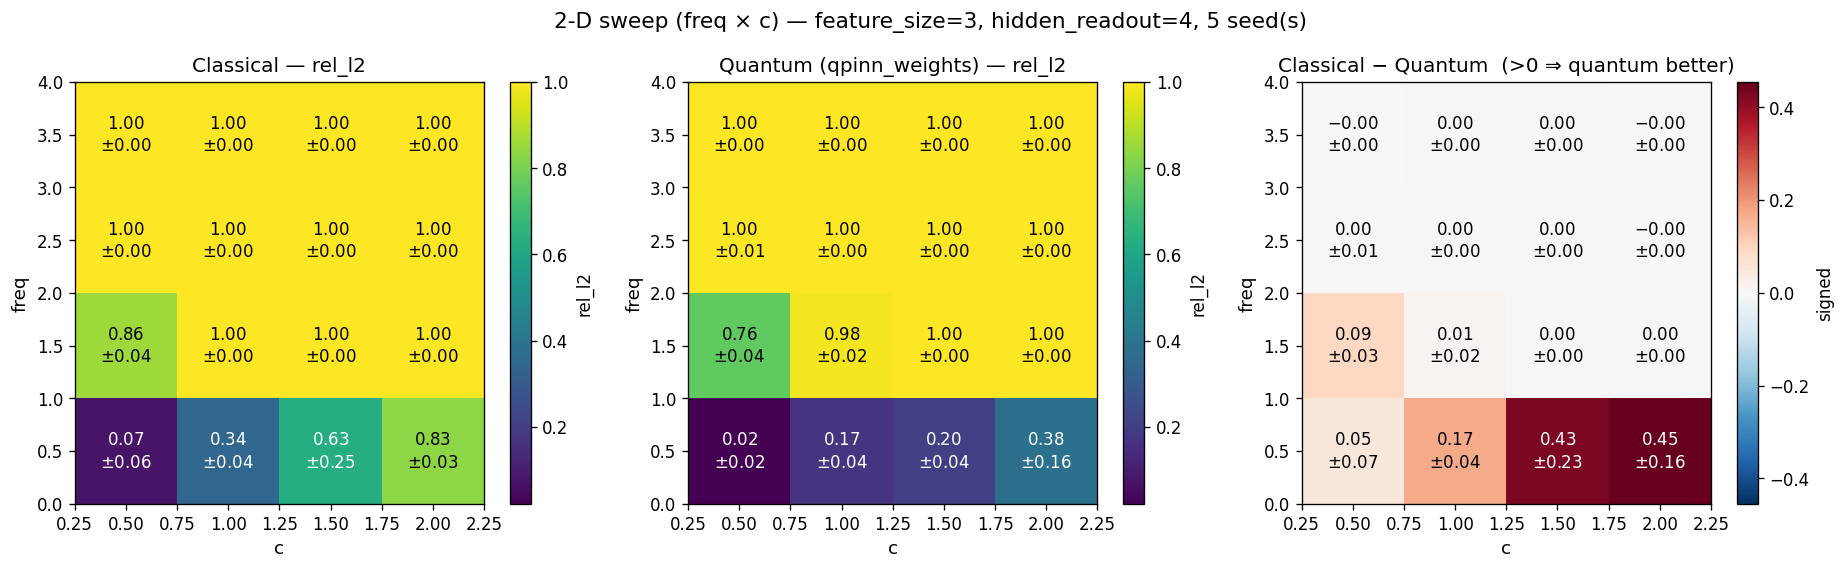

In [48]:
plot_2d_sweep(
    wave_sweep, metric="rel_l2", diff_mode="signed",
    save_path=f"../figures/fourier_demo/wave_sweep_freq_c_rel_l2_FS={FEATURE_SIZE_2D_GUESS}_.png",
)


In [ ]:
#from src.models import MerlinTunableEntropy
#from src.pde import HeatEquation

%load_ext autoreload
%autoreload 2
from src.sweep import run_depth_sweep
from src.plotter import plot_depth_sweep, plot_depth_sweep_training_curves

FREQ = 5.0            # hardest point in the section-1 sweep where the gap was largest
FEATURE_SIZE = 4      # matches the paper's reference configuration (F=4)
#DEPTHS = [4, 3, 2, 1]
DEPTHS = [1, 2, 3, 4]
#DEPTHS = [2]

heat_pde = HeatEquation(freq=FREQ)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
smoke_result = run_depth_sweep(
    pde=heat_pde,
    depths=DEPTHS,
    feature_size=FEATURE_SIZE,
    seeds=[421],
    epochs=50,
)

plot_depth_sweep(smoke_result, metric="rel_l2", target_frequency=2 * FREQ, show=True)

L=5: quantum_params=662  bound=±15  classical match -> quantum_output_size=10 hidden_readout=38 params=662 (diff=+0)
Parameters — total: 662  trainable: 662

Training for 50 epochs on cpu  (dtype=torch.float32)
Epoch     1/50 | Loss: 5.2630e+00 | PDE: 1.36e-04 | Cons: 1.09e-02 | IC: 5.26e-01 | BC: 0.00e+00 | Time: 0.2s


KeyboardInterrupt: 

In [9]:
SEEDS = [42, 666, 69]
EPOCHS = 6000

depth_result = run_depth_sweep(
    pde=heat_pde,
    depths=DEPTHS,
    feature_size=FEATURE_SIZE,
    seeds=SEEDS,
    epochs=EPOCHS,
    log_every=50,
)

L=2: quantum_params=398  bound=±6  classical match -> quantum_output_size=2 hidden_readout=54 params=398 (diff=+0)
Parameters — total: 398  trainable: 398

Training for 6000 epochs on cpu  (dtype=torch.float32)
Epoch     1/6000 | Loss: 5.0491e+00 | PDE: 6.60e-04 | Cons: 1.31e-01 | IC: 4.98e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch    50/6000 | Loss: 4.6696e+00 | PDE: 1.60e-06 | Cons: 1.18e-03 | IC: 4.67e-01 | BC: 0.00e+00 | Time: 5.4s
Epoch   100/6000 | Loss: 5.0118e+00 | PDE: 4.14e-07 | Cons: 1.01e-03 | IC: 5.01e-01 | BC: 0.00e+00 | Time: 10.8s
Epoch   150/6000 | Loss: 4.8178e+00 | PDE: 2.50e-06 | Cons: 1.11e-03 | IC: 4.82e-01 | BC: 0.00e+00 | Time: 16.1s
Epoch   200/6000 | Loss: 5.4297e+00 | PDE: 4.94e-05 | Cons: 1.07e-03 | IC: 5.43e-01 | BC: 0.00e+00 | Time: 21.4s
Epoch   250/6000 | Loss: 5.0767e+00 | PDE: 1.27e-06 | Cons: 4.73e-04 | IC: 5.08e-01 | BC: 0.00e+00 | Time: 26.7s
Epoch   300/6000 | Loss: 4.8974e+00 | PDE: 1.12e-06 | Cons: 1.16e-03 | IC: 4.90e-01 | BC: 0.00e+00 | Time: 32.1s


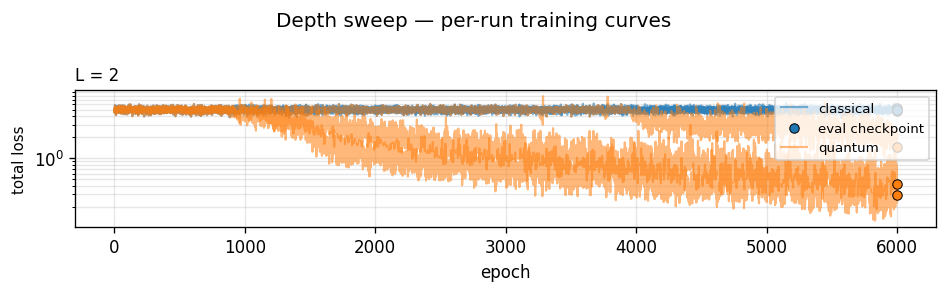

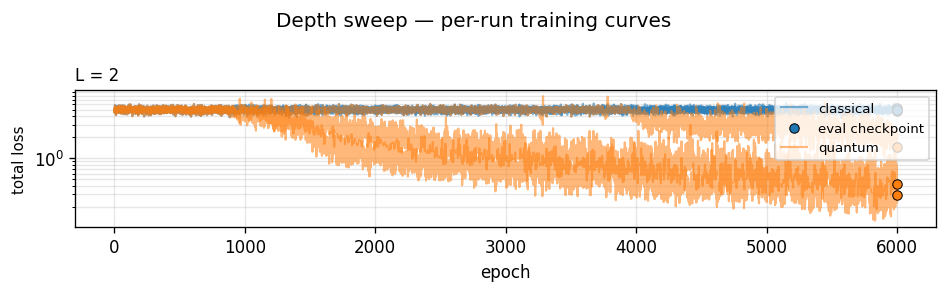

In [10]:
plot_depth_sweep_training_curves(depth_result, component="total")

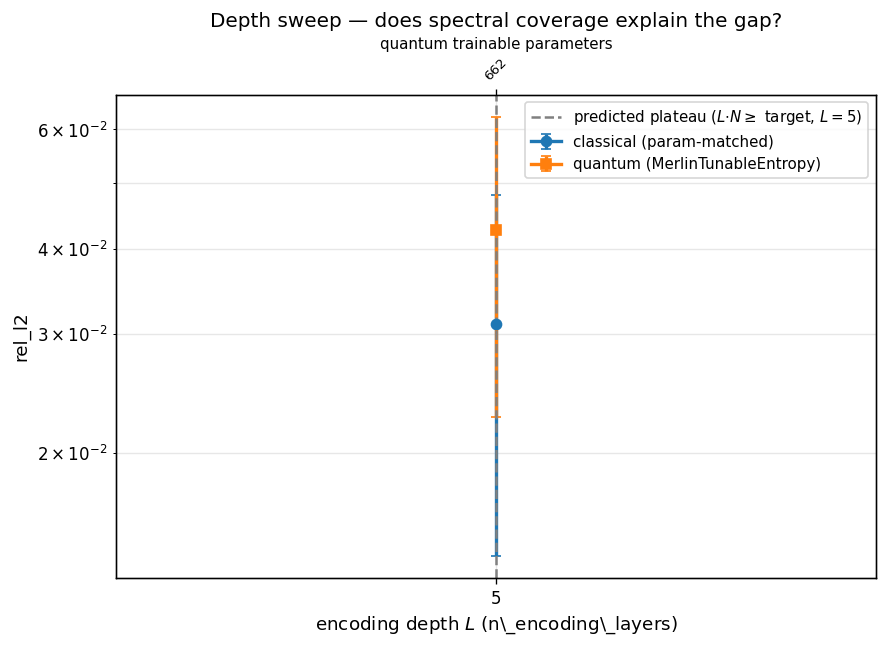

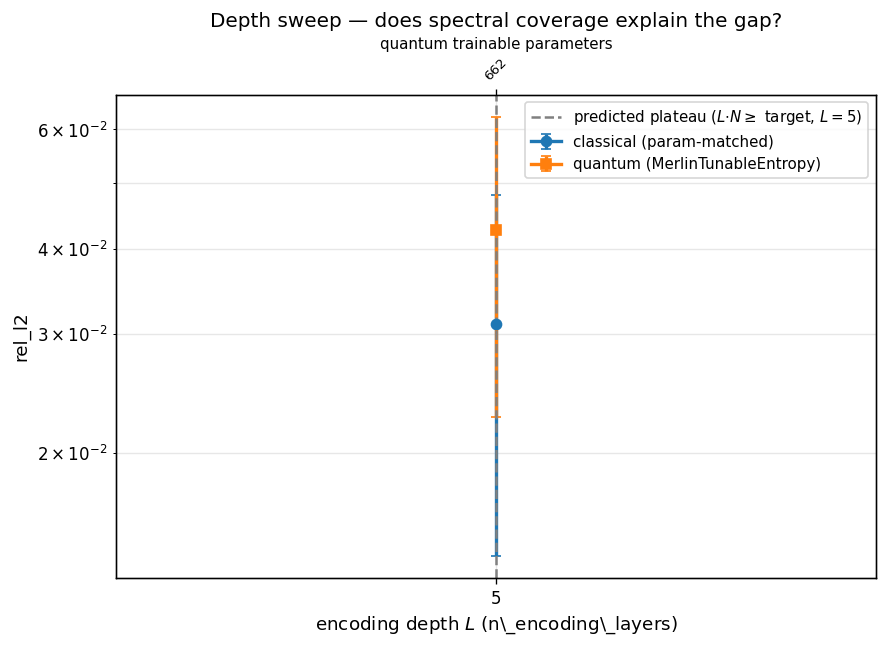

In [18]:
plot_depth_sweep(depth_result, metric="rel_l2", target_frequency=2 * FREQ, show=True)

In [11]:
from spectral_bandwidth import (
    verify_input_mapping,
    quantum_layer_spectrum,
    effective_bandwidth,
    fraction_of_ceiling_used,
    spectral_second_moment,
    plot_spectrum_by_layers,
    plot_bandwidth_vs_layers,
    plot_analytic_vs_effective_gap,
)

In [14]:
SPECTRAL_DEPTHS = DEPTHS  # reuse Section 4's depths for direct comparison
HIDDEN_FEATURE = 16
HIDDEN_READOUT = 4

probe_model = MerlinTunableEntropy(
    feature_size=FEATURE_SIZE, hidden_feature=HIDDEN_FEATURE,
    hidden_readout=HIDDEN_READOUT, n_encoding_layers=max(SPECTRAL_DEPTHS), pde=heat_pde,
)
deltas = verify_input_mapping(probe_model, feature_size=FEATURE_SIZE, n_encoding_layers=max(SPECTRAL_DEPTHS))
suspicious = {k: v for k, v in deltas.items() if v < 1e-6}
print(f"{len(deltas)} (layer, feature) slots checked, {len(suspicious)} suspicious (delta < 1e-6)")
if suspicious:
    print("  WARNING -- these slots look dead, investigate before trusting the spectra below:")
    for k, v in suspicious.items():
        print(f"    {k}: delta={v:.2e}")


8 (layer, feature) slots checked, 0 suspicious (delta < 1e-6)


In [ ]:
SPECTRAL_EPOCHS = 6000  # match Section 4's EPOCHS; lower for a smoke test first
FEATURE_INDEX = 0        # which of the FEATURE_SIZE encoded scalars to probe

spectra_init = {}
spectra_trained = {}

for L in SPECTRAL_DEPTHS:
    torch.manual_seed(42)
    np.random.seed(42)
    model = MerlinTunableEntropy(
        feature_size=FEATURE_SIZE, hidden_feature=HIDDEN_FEATURE,
        hidden_readout=HIDDEN_READOUT, n_encoding_layers=L, pde=heat_pde,
    )

    spectra_init[L] = quantum_layer_spectrum(
        model, feature_size=FEATURE_SIZE, n_encoding_layers=L,
        feature_index=FEATURE_INDEX, trained=False,
    )

    train(model=model, pde=heat_pde, loss_fn=total_loss, seed=42,
          epochs=SPECTRAL_EPOCHS, log_every=50)

    spectra_trained[L] = quantum_layer_spectrum(
        model, feature_size=FEATURE_SIZE, n_encoding_layers=L,
        feature_index=FEATURE_INDEX, trained=True,
    )

    r_i, r_t = spectra_init[L], spectra_trained[L]
    print(
        f"L={L}  bound=±{r_i.analytic_bound}  "
        f"init: eff_bw={effective_bandwidth(r_i):.1f} "
        f"({fraction_of_ceiling_used(r_i):.0%} of ceiling)  |  "
        f"trained: eff_bw={effective_bandwidth(r_t):.1f} "
        f"({fraction_of_ceiling_used(r_t):.0%} of ceiling)"
    )

Parameters — total: 398  trainable: 398

Training for 1000 epochs on cpu  (dtype=torch.float32)
Epoch     1/1000 | Loss: 5.0491e+00 | PDE: 6.60e-04 | Cons: 1.31e-01 | IC: 4.98e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch    50/1000 | Loss: 4.6693e+00 | PDE: 2.04e-06 | Cons: 1.47e-03 | IC: 4.67e-01 | BC: 0.00e+00 | Time: 5.5s
Epoch   100/1000 | Loss: 5.0026e+00 | PDE: 8.02e-07 | Cons: 3.40e-05 | IC: 5.00e-01 | BC: 0.00e+00 | Time: 11.1s
Epoch   150/1000 | Loss: 4.8164e+00 | PDE: 3.51e-06 | Cons: 4.60e-04 | IC: 4.82e-01 | BC: 0.00e+00 | Time: 16.6s
Epoch   200/1000 | Loss: 5.4362e+00 | PDE: 1.16e-05 | Cons: 9.30e-04 | IC: 5.44e-01 | BC: 0.00e+00 | Time: 22.2s
Epoch   250/1000 | Loss: 5.0762e+00 | PDE: 7.26e-07 | Cons: 3.01e-04 | IC: 5.08e-01 | BC: 0.00e+00 | Time: 27.7s
Epoch   300/1000 | Loss: 4.8965e+00 | PDE: 5.87e-06 | Cons: 4.90e-04 | IC: 4.90e-01 | BC: 0.00e+00 | Time: 33.1s
Epoch   350/1000 | Loss: 4.9578e+00 | PDE: 1.02e-06 | Cons: 6.62e-04 | IC: 4.96e-01 | BC: 0.00e+00 | Time: 38.6s
Ep

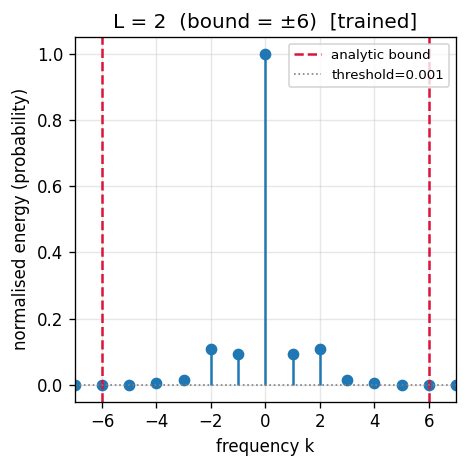

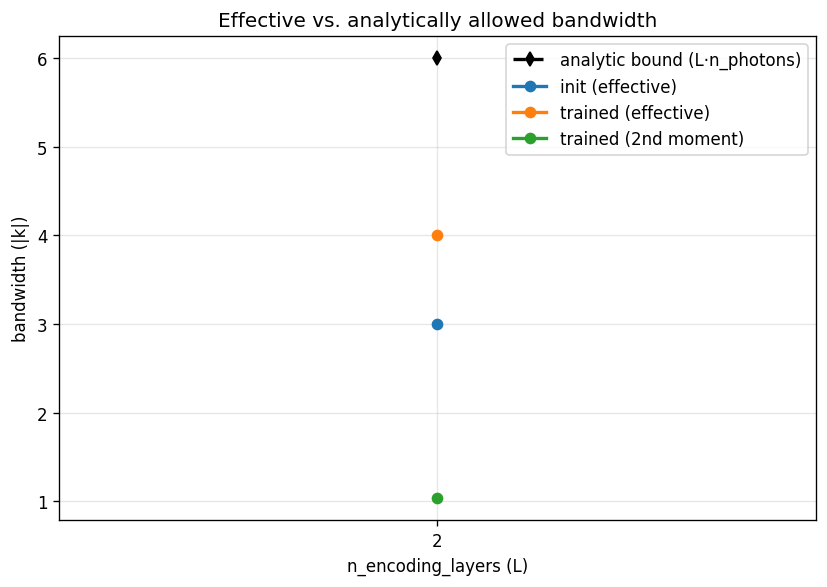

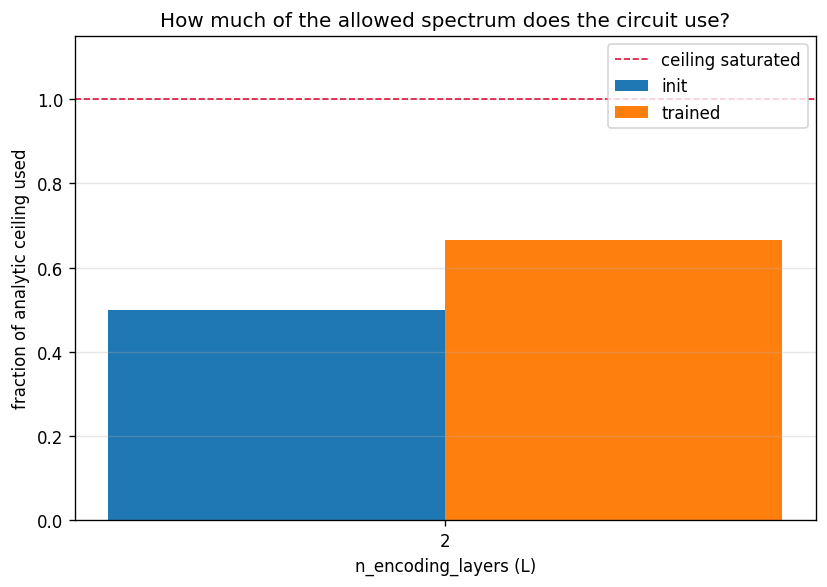

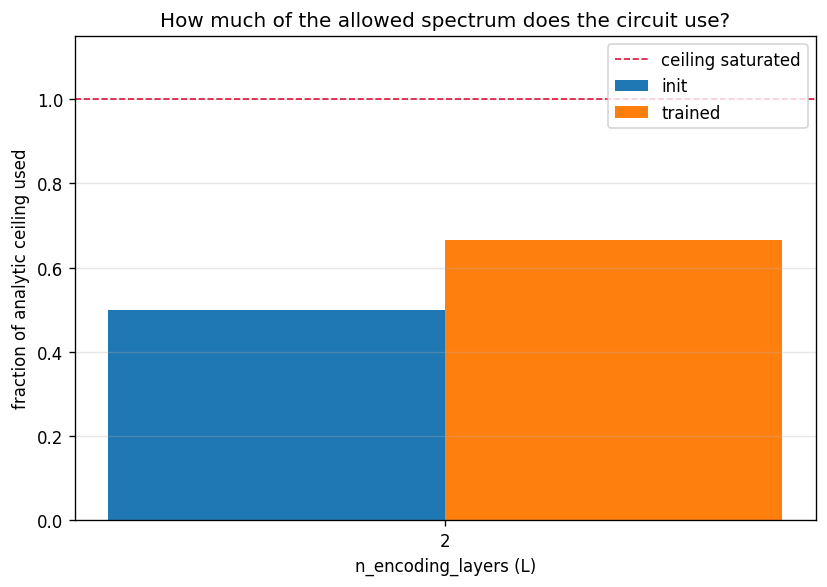

In [17]:
plot_spectrum_by_layers(spectra_trained)

plot_bandwidth_vs_layers(
    layers_list=SPECTRAL_DEPTHS,
    series={
        "init (effective)":    [effective_bandwidth(spectra_init[L]) for L in SPECTRAL_DEPTHS],
        "trained (effective)": [effective_bandwidth(spectra_trained[L]) for L in SPECTRAL_DEPTHS],
        "trained (2nd moment)": [spectral_second_moment(spectra_trained[L]) for L in SPECTRAL_DEPTHS],
    },
    analytic_bounds=[spectra_trained[L].analytic_bound for L in SPECTRAL_DEPTHS],
)

plot_analytic_vs_effective_gap(
    layers_list=SPECTRAL_DEPTHS,
    series={
        "init":    [fraction_of_ceiling_used(spectra_init[L]) for L in SPECTRAL_DEPTHS],
        "trained": [fraction_of_ceiling_used(spectra_trained[L]) for L in SPECTRAL_DEPTHS],
    },
)